### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [961]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [962]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie0.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    # "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [963]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794000,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,62.1936,0,A1,A
1,45493161.0,3850.546,106.794000,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,62.2044,0,A1,A
2,45493163.5,3850.589,106.794000,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,62.2116,0,A1,A
3,45493166.0,3850.633,106.794000,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,62.2224,0,A1,A
4,45493168.5,3850.676,106.794000,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
288458,41563778.5,5512.852,10.355333,0.6512,-1.5795,-48.0806,-1.78920,0.16438,10.33153,-0.00936,-0.01235,-0.02487,33.9372,0,B4,B
288459,41563781.0,5512.875,11.012904,0.6481,-1.5840,-47.9881,-1.88369,-0.02342,10.76440,-0.00575,-0.00767,-0.02849,33.9372,0,B4,B
288460,41563783.5,5512.899,10.800525,0.6452,-1.5904,-47.8951,-1.92509,-0.06587,10.62556,-0.00451,-0.02198,-0.02490,33.9372,0,B4,B
288461,41563786.0,5512.922,10.374600,0.6427,-1.5977,-47.8027,-1.60182,0.24200,10.34438,-0.00214,-0.02739,-0.02887,33.9408,0,B4,B


In [964]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4']


In [965]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794000,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,62.1936,0,A1,A
1,45493161.0,3850.546,106.794000,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,62.2044,0,A1,A
2,45493163.5,3850.589,106.794000,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,62.2116,0,A1,A
3,45493166.0,3850.633,106.794000,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,62.2224,0,A1,A
4,45493168.5,3850.676,106.794000,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
288458,41563778.5,5512.852,10.355333,0.6512,-1.5795,-48.0806,-1.78920,0.16438,10.33153,-0.00936,-0.01235,-0.02487,33.9372,0,B4,B
288459,41563781.0,5512.875,11.012904,0.6481,-1.5840,-47.9881,-1.88369,-0.02342,10.76440,-0.00575,-0.00767,-0.02849,33.9372,0,B4,B
288460,41563783.5,5512.899,10.800525,0.6452,-1.5904,-47.8951,-1.92509,-0.06587,10.62556,-0.00451,-0.02198,-0.02490,33.9372,0,B4,B
288461,41563786.0,5512.922,10.374600,0.6427,-1.5977,-47.8027,-1.60182,0.24200,10.34438,-0.00214,-0.02739,-0.02887,33.9408,0,B4,B


In [966]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh"]


In [967]:
# This code makes row windows of the data, with a given window size and stride. It returns the X and y values for each window.

# def make_row_windows(run_df, win=100, stride=20):
#     run_df = run_df.sort_values("Timer(ms)")
#     X = run_df[feature_cols].to_numpy(np.float32)
#     y = run_df["Frostbumps"].to_numpy()

#     X_clips, y_clips = [], []
#     for start in range(0, len(X) - win + 1, stride):
#         end = start + win
#         X_clips.append(X[start:end])
#         y_clips.append(y[start:end].max())

#     return np.array(X_clips), np.array(y_clips)

In [968]:
def make_row_windows(run_df, win=0, stride=0, min_percentage=0.1):
    run_df = run_df.sort_values("Timer(ms)")

    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []

    for start in range(0, len(X) - win + 1, stride):
        end = start + win

        X_clips.append(X[start:end])

        bump_percentage = y[start:end].mean()
        y_clips.append(int(bump_percentage >= min_percentage))

    return np.array(X_clips), np.array(y_clips)

In [969]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=100, stride=20)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [970]:
# Checking the number of windows per run

for run in ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]:
    X, y = get_clips([run])

    print(
        f"{run}: {len(y)} windows, "
        f"{y.mean():.1%} positive"
    )

A1: 2839 windows, 22.1% positive
A2: 3769 windows, 21.1% positive
A3: 5730 windows, 19.2% positive
B1: 317 windows, 59.9% positive
B2: 379 windows, 44.9% positive
B3: 457 windows, 46.8% positive
B4: 902 windows, 34.9% positive


In [971]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A3", "B3", "B4", "B1"])
Xva, yva = get_clips(["B2", "A2"])
Xte, yte = get_clips(["A1"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(7406, 100, 9) (4148, 100, 9) (2839, 100, 9)
0.2453416149068323 0.23240115718418514 0.220852412821416


In [972]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

n_features = Xtr.shape[-1]      # 9 now

scaler = StandardScaler()
scaler.fit(Xtr.reshape(-1, n_features))

Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

## NN stuff starts here


In [973]:
# import keras_tuner
# from tensorflow import keras
# from tensorflow.keras import layers

# def build_model(hp):
#     norm = layers.Normalization(axis=-1)
#     norm.adapt(Xtr)

#     f1 = hp.Choice("filters1", [8, 16, 32])
#     f2 = hp.Choice("filters2", [8, 16, 32])
#     k1 = hp.Choice("kernel1", [5, 9, 15])
#     k2 = hp.Choice("kernel2", [3, 5, 9])
#     l2 = hp.Choice("l2", [0.0, 1e-4, 1e-3, 1e-2])
#     drop = hp.Float("dropout", 0.2, 0.6, step=0.1)
#     lr = hp.Choice("lr", [1e-4, 3e-4, 1e-3])
#     use_dense = hp.Boolean("hidden_dense")

#     reg = keras.regularizers.l2(l2) if l2 > 0 else None

#     m = [layers.Input(shape=Xtr.shape[1:]), norm,
#          layers.Conv1D(f1, k1, padding="same", activation="relu", kernel_regularizer=reg),
#          layers.MaxPooling1D(2),
#          layers.Conv1D(f2, k2, padding="same", activation="relu", kernel_regularizer=reg),
#          layers.GlobalMaxPooling1D(),
#          layers.Dropout(drop)]
#     if use_dense:
#         m.append(layers.Dense(16, activation="relu", kernel_regularizer=reg))
#     m.append(layers.Dense(1, activation="sigmoid"))

#     model = keras.Sequential(m)
#     model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
#                   metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
#     return model

# tuner = keras_tuner.Hyperband(
#     build_model,
#     objective=keras_tuner.Objective("val_pr_auc", direction="max"),
#     max_epochs=60, factor=3,
#     seed=3, directory="kt", project_name="frostbumps", overwrite=True)

# tuner.search(
#     Xtr, ytr, validation_data=(Xva, yva), batch_size=32,
#     class_weight={0: 1.0, 1: float(w)},
#     callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=10)])

In [974]:
# # 1. The best hyperparameters
# best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
# print(best_hp.values)          # dict: {'filters1': 16, 'kernel1': 9, ...}

# # 2. Overview of the top trials
# tuner.results_summary(num_trials=5)

# # 3. The best model (already trained, weights from the best epoch)
# best_model = tuner.get_best_models(num_models=1)[0]

In [975]:
# import optuna
# import numpy as np
# import keras
# from keras import layers
# from sklearn.metrics import average_precision_score


# def build_model():
#     norm = layers.Normalization(axis=-1)
#     norm.adapt(Xtr)

#     model = keras.Sequential([
#         layers.Input(shape=Xtr.shape[1:]),
#         norm,
#         layers.Conv1D(16, 15, padding="same", activation="relu"),
#         layers.MaxPooling1D(2),
#         layers.Conv1D(32, 5, padding="same", activation="relu"),
#         layers.GlobalMaxPooling1D(),
#         layers.Dropout(0.4),
#         layers.Dense(1, activation="sigmoid")
#     ])

#     model.compile(
#         optimizer=keras.optimizers.Adam(1e-4),
#         loss="binary_crossentropy",
#         metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")]
#     )

#     return model


# def objective(trial):
#     weight = trial.suggest_float("weight", 1, 10, log=True)

#     scores = []

#     for seed in [0, 1, 2]:
#         keras.utils.set_random_seed(seed)

#         model = build_model()

#         model.fit(
#             Xtr, ytr,
#             validation_data=(Xva, yva),
#             epochs=100,
#             batch_size=32,
#             verbose=0,
#             class_weight={0: 1, 1: weight},
#             callbacks=[
#                 keras.callbacks.EarlyStopping(
#                     monitor="val_pr_auc",
#                     mode="max",
#                     patience=15,
#                     restore_best_weights=True
#                 )
#             ]
#         )

#         predictions = model.predict(Xva, verbose=0).ravel()
#         scores.append(average_precision_score(yva, predictions))

#     return np.mean(scores)


# study = optuna.create_study(
#     direction="maximize",
#     sampler=optuna.samplers.TPESampler(seed=3)
# )

# study.optimize(objective, n_trials=50)

# print("Best class weight:", study.best_params["weight"])
# print("Best average precision:", study.best_value)

# RESULTS:
# Best class weight: 1.5640968184980821
# Best average precision: 0.628173389193539

In [976]:
from tensorflow import keras
from tensorflow.keras import layers


optunaweights = {0: 1, 1: 1.564}
seed=29104

keras.utils.set_random_seed(seed)  # first thing, before building or shuffling anything


'''Trial 0089 summary
Hyperparameters:
filters1: 16
filters2: 32
kernel1: 15
kernel2: 5
l2: 0.001
dropout: 0.4
lr: 0.0001
hidden_dense: False
tuner/epochs: 60
tuner/initial_epoch: 0
tuner/bracket: 0
tuner/round: 0
Score: 0.7190312147140503'''


model = keras.Sequential([
    layers.Input(shape=Xtr.shape[1:]),
    layers.Conv1D(8, 5, padding="same", activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3)),
    layers.MaxPooling1D(2),
    layers.Conv1D(16, 5, padding="same", activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3)),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.4),
    # layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

optimizer = keras.optimizers.Adam(learning_rate=0.0001)

model.compile(optimizer=optimizer, loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])


history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=50, batch_size=32,
          class_weight=optunaweights,
          callbacks=[keras.callbacks.EarlyStopping(
              monitor="val_pr_auc", patience=10, restore_best_weights=True)]
        )



Epoch 1/50
232/232 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.8879 - pr_auc: 0.2968 - val_loss: 0.6949 - val_pr_auc: 0.3102
Epoch 2/50
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.8106 - pr_auc: 0.3270 - val_loss: 0.7031 - val_pr_auc: 0.3965
Epoch 3/50
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.7563 - pr_auc: 0.3907 - val_loss: 0.7351 - val_pr_auc: 0.4487
Epoch 4/50
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.7297 - pr_auc: 0.4363 - val_loss: 0.7919 - val_pr_auc: 0.4842
Epoch 5/50
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6971 - pr_auc: 0.4885 - val_loss: 0.8451 - val_pr_auc: 0.5086
Epoch 6/50
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6765 - pr_auc: 0.5181 - val_loss: 0.8867 - val_pr_auc: 0.5229
Epoch 7/50
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6639 - pr_auc: 0.5341 - val_loss: 0.9401 - val_pr_auc: 0.5390
Epoch 8/50
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.6435 - pr_auc: 0.5621 - val_loss: 0.9822 - val_pr_auc: 0.5515
Epoch 9/

KeyboardInterrupt: 

In [ ]:
# Trial 4 finished with value: 0.6799844171905752 and parameters: {'w_pos': 1.87785271154023}. Best is trial 4 with value: 0.6799844171905752.


In [ ]:
model.summary()

Model: "sequential_259"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_518 (Conv1D)             │ (None, 100, 16)        │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_259               │ (None, 50, 16)         │             0 │
│ (MaxPooling1D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_519 (Conv1D)             │ (None, 50, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_259        │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_259 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_259 (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,405 (56.27 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,604 (37.52 KB)

In [ ]:
p = model.predict(Xva).ravel()
print("val positive rate:", yva.mean())
print("pred prob: min/median/max", p.min(), np.median(p), p.max())
print("fraction predicted positive at 0.5:", (p > 0.5).mean())

from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score
print(confusion_matrix(yva, p > 0.5))
print("ROC-AUC:", roc_auc_score(yva, p), "PR-AUC:", average_precision_score(yva, p))

 38/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
val positive rate: 0.23240115718418514
pred prob: min/median/max 0.0017952961 0.8192955 0.99999404
fraction predicted positive at 0.5: 0.9447926711668274
[[ 139 3045]
 [  90  874]]
ROC-AUC: 0.7261381466460936 PR-AUC: 0.6079145837299447


In [ ]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Get predicted probabilities
y_pred_proba = model.predict(Xte).ravel()

# Calculate AUC scores
pr_auc = average_precision_score(yte, y_pred_proba)
roc_auc = roc_auc_score(yte, y_pred_proba)

print(f"PR-AUC:  {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

19/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step  

89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
PR-AUC:  0.6103
ROC-AUC: 0.7557


<Axes: >

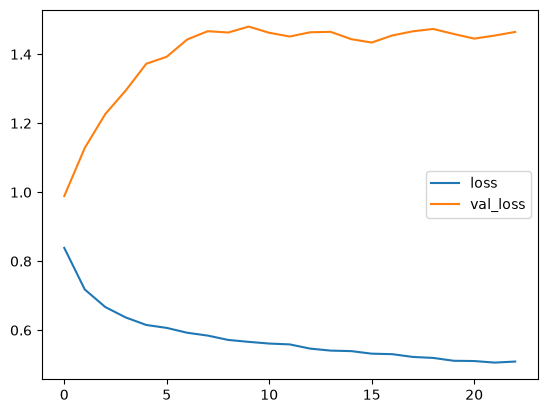

In [ ]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

In [ ]:
# compare the final model loss/accuracy/evaluation values
# the values should match mostly
print("Test data evaluation:")
print(model.evaluate(Xte, yte, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(Xtr, ytr, verbose=0))

Test data evaluation:
[2.240647077560425, 0.5806169509887695]

Train data evaluation:
[0.4256494343280792, 0.7322843074798584]


In [ ]:
test_predictions = model.predict(Xte).ravel()

test_predictions = (test_predictions >= 0.7).astype(int)


89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


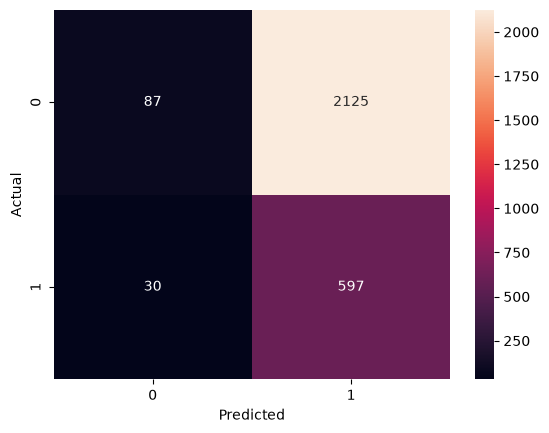

In [ ]:


# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(yte, test_predictions), annot=True, fmt='g')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(Xte).ravel() >= 0.6).astype(int)

print(confusion_matrix(yte, y_pred))
print(classification_report(yte, y_pred))

acc = accuracy_score(yte, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
[[  74 2138]
 [  27  600]]
              precision    recall  f1-score   support

           0       0.73      0.03      0.06      2212
           1       0.22      0.96      0.36       627

    accuracy                           0.24      2839
   macro avg       0.48      0.50      0.21      2839
weighted avg       0.62      0.24      0.13      2839


Model overall accuracy: 24.09%


In [ ]:
y_prob = model.predict(Xte).ravel()

print("Minimum:", y_prob.min())
print("Maximum:", y_prob.max())
print("Mean:", y_prob.mean())

y_pred = (y_prob >= 0.5).astype(int)

print("Predicted classes:")
print(np.unique(y_pred, return_counts=True))

89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Minimum: 0.006144882
Maximum: 0.99999785
Mean: 0.9074692
Predicted classes:
(array([0, 1]), array([  90, 2749]))


In [ ]:
y_prob = model.predict(Xte).ravel()

print("Actual frost bumps:", np.sum(yte == 1))
print("Predicted frost bumps:", np.sum(y_prob >= 0.5))

print("\nProbabilities for actual frost bumps:")
print(y_prob[yte == 1])

89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Actual frost bumps: 627
Predicted frost bumps: 2749

Probabilities for actual frost bumps:
[0.92397827 0.9212238  0.93177813 0.9478401  0.9830055  0.99545586
 0.99684596 0.994909   0.99568224 0.9978393  0.9991173  0.99936926
 0.9986504  0.99687934 0.99343485 0.99676657 0.9987458  0.9988168
 0.99658984 0.99694866 0.9986918  0.9989146  0.99789655 0.99603426
 0.9955221  0.9930098  0.999896   0.99999034 0.9999831  0.9999027
 0.99991953 0.99997866 0.9999835  0.9999441  0.9992029  0.99576557
 0.99421555 0.9916401  0.99511486 0.9963301  0.9950662  0.9934751
 0.996287   0.99748755 0.9977546  0.9956721  0.9892914  0.9815084
 0.97393036 0.96630806 0.95677215 0.9666393  0.9614781  0.9618527
 0.9488917  0.96495247 0.9515421  0.95242876 0.9528553  0.9534216
 0.9828843  0.9786732  0.9809939  0.9665005  0.9523136  0.99027723
 0.9973816  0.99897397 0.9988738  0.9981381  0.9998123  0.99992704
 0.99995786 0.9996582  0.9994446  0.9997031  0.99983436 0.9996096
 0.998